# TP 2 — Détection du sarcasme arabe (ArSarcasm-v2)

Ce notebook suit les parties A à G de l'énoncé. **Exécuter les cellules dans l'ordre.** Le test officiel est chargé au début uniquement pour l'audit du texte et la déduplication ; ses étiquettes ne sont consultées qu'en partie F. Les résultats et prédictions sont enregistrés dans `results/` et `predictions/` sur le système de fichiers **du noyau**. Avec un noyau Colab distant, `/content` est temporaire. Avant la configuration, monter Drive puis définir un dossier persistant si vous voulez conserver les checkpoints entre sessions :

```python
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ['TP2_OUTPUT_DIR'] = '/content/drive/MyDrive/TP2_Sarcasme'
```

Sources : [ArSarcasm-v2](https://github.com/iabufarha/ArSarcasm-v2), [AraVec](https://github.com/bakrianoo/aravec), [AraBERT-Twitter](https://huggingface.co/aubmindlab/bert-base-arabertv02-twitter), [MARBERTv2](https://huggingface.co/UBC-NLP/MARBERTv2). Les sections B–F téléchargent des modèles volumineux et exigent idéalement un GPU T4. Aucun score n'est inventé : chaque tableau est produit par exécution.

**Protocole.** Split officiel train/test ; 10 % de la partie train pour validation, stratifiés, graine 42. Prétraitements, vocabulaire, poids, seuil et choix d'hyperparamètres calculés sur train/val seulement. Les expériences coûtant plusieurs heures sont lancées par leurs cellules dédiées ; les commutateurs plus bas permettent une exécution progressive.

## 0. Dépendances et configuration

In [3]:
# Vérification rapide du noyau réellement utilisé par VS Code.
import os
print('Colab :', os.environ.get('COLAB_RELEASE_TAG'))
print('Dossier du noyau :', os.getcwd())

Colab : release-colab-external-images_20260715-060047_RC00
Dossier du noyau : /content


In [4]:
# Sur Colab : exécuter une fois, puis redémarrer le noyau si pip le demande.
import importlib.util, subprocess, sys
packages = {
    'torch': 'torch', 'transformers': 'transformers>=4.45,<5',
    'datasets': 'datasets', 'accelerate': 'accelerate',
    'gensim': 'gensim', 'emoji': 'emoji', 'arabert': 'arabert',
    'sklearn': 'scikit-learn', 'pandas': 'pandas',
    'matplotlib': 'matplotlib', 'scipy': 'scipy', 'joblib': 'joblib'
}
missing = [spec for mod, spec in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dépendances disponibles. Python :', sys.version.split()[0])

Dépendances disponibles. Python : 3.12.13


In [5]:
import os, re, csv, gc, math, time, random, warnings, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    except ImportError: pass
seed_everything()
ROOT = Path(os.environ.get('TP2_OUTPUT_DIR', '.')).resolve()
for dirname in ['data', 'results', 'predictions', 'models', 'figures']:
    (ROOT / dirname).mkdir(parents=True, exist_ok=True)
print('Sorties :', ROOT)
print('Colab :', bool(os.environ.get('COLAB_RELEASE_TAG')))

# Les cellules GPU longues sont explicites ; choisir False pour un premier passage rapide.
RUN_ZERO_SHOT = True
RUN_STATIC = True
RUN_FROZEN = True
RUN_FINETUNE = True
RUN_GENERALIZATION = True
PLM_NAMES = ['aubmindlab/bert-base-arabertv02-twitter', 'UBC-NLP/MARBERTv2']
FINAL_SEEDS = [42, 123, 2025]
MAX_LEN = 128
EPOCHS_STATIC = 8
EPOCHS_PLM = 4
BATCH_PLM = 16  # 32 avec accumulation de 2 sur T4
ACCUM_STEPS = 2

Sorties : /content
Colab : True


## 1. Données et audit brut — aucune étiquette du test utilisée avant F

In [6]:
BASE = 'https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/'
for name in ['training_data.csv', 'testing_data.csv']:
    path = ROOT / 'data' / name
    if not path.exists():
        pd.read_csv(BASE + name).to_csv(path, index=False)
full = pd.read_csv(ROOT / 'data/training_data.csv')
test_raw = pd.read_csv(ROOT / 'data/testing_data.csv')
assert list(full.columns) == list(test_raw.columns) == ['tweet','sarcasm','sentiment','dialect']
assert len(full) == 12548 and len(test_raw) == 3000
full['id'], test_raw['id'] = range(len(full)), range(len(test_raw))
train, val = train_test_split(full, test_size=0.10, random_state=42,
                              stratify=full['sarcasm'])
train, val = train.copy(), val.copy()
print('train, val, test :', len(train), len(val), len(test_raw))
print('30 tweets bruts de train :'); display(train[['id','tweet']].head(30))
print('30 tweets bruts de test (texte seulement) :'); display(test_raw[['id','tweet']].head(30))

train, val, test : 11293 1255 3000
30 tweets bruts de train :


,id,tweet
2474,2474,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال..."
12107,12107,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري..."
2135,2135,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...
640,640,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد..."
6766,6766,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x..."
5267,5267,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال ا..."
1318,1318,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من..."
10003,10003,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من ..."
4557,4557,بموت ضحك عطو فرصه لغيركم يحزن
49,49,في قلبي رجل M❤️ يلغ...


30 tweets bruts de test (texte seulement) :


,id,tweet
0,0,اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يف...
1,1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26
2,2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️
3,3,ابشركم طلقت السات 😘.
4,4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...
5,5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه رو...
6,6,اختطاف الأطفال في #الجزائر..العثور على جثة مشو...
7,7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراس...
8,8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت ...
9,9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنال...


In [7]:
import emoji
URL_RE = re.compile(r'https?://\S+|www\.\S+', re.I)
MENTION_RE = re.compile(r'(?<!\w)@[\w_]+', re.UNICODE)
HASHTAG_RE = re.compile(r'(?<!\w)#[\w_]+', re.UNICODE)
LAUGH_RE = re.compile(r'(?:[هھﮪﮬ]{3,}|(?:هه|ھھ){2,}|(?:lol|haha){2,})', re.I)
PUNCT_RE = re.compile(r'[!?؟،.]{2,}')
DIAC_RE = re.compile(r'[\u0610-\u061A\u064B-\u065F\u0670]')
TATWEEL_RE = re.compile('ـ')
REPEAT_RE = re.compile(r'([\u0621-\u064A])\1{2,}')
LATIN_RE = re.compile(r'[A-Za-z]')
INDIC_RE = re.compile(r'[٠-٩۰-۹]')
WRAPPED_RE = re.compile(r'^\s*["“](.*)["”]\s*$', re.S)

def strip_export_quotes(text):
    text = str(text)
    m = WRAPPED_RE.match(text)
    return m.group(1) if m else text

def audit_flags(text):
    t = str(text)
    return {'url': bool(URL_RE.search(t)), 'mention': bool(MENTION_RE.search(t)),
            'hashtag': bool(HASHTAG_RE.search(t)), 'emoji': bool(emoji.emoji_count(t)),
            'rire': bool(LAUGH_RE.search(t)), 'ponctuation_repetee': bool(PUNCT_RE.search(t)),
            'diacritiques': bool(DIAC_RE.search(t)), 'tatweel': bool(TATWEEL_RE.search(t)),
            'lettres_repetees': bool(REPEAT_RE.search(t)), 'latin': bool(LATIN_RE.search(t)),
            'chiffres_indiens': bool(INDIC_RE.search(t)),
            'guillemets_export': bool(WRAPPED_RE.match(t))}

train_flags = pd.DataFrame([audit_flags(t) for t in train.tweet], index=train.index)
test_flags = pd.DataFrame([audit_flags(t) for t in test_raw.tweet], index=test_raw.index)
display(pd.DataFrame({'train_n': train_flags.sum(), 'train_%': train_flags.mean()*100,
                      'test_n': test_flags.sum(), 'test_%': test_flags.mean()*100}).round(2))
print('Corrélation (train uniquement) :')
display(pd.DataFrame({'n': train_flags.sum(),
                      'taux_sarcasme_avec': [train.loc[train_flags[k], 'sarcasm'].mean() for k in train_flags],
                      'taux_sarcasme_sans': [train.loc[~train_flags[k], 'sarcasm'].mean() for k in train_flags]}))
print('Artefact de format : guillemets englobant certains tweets (visible dès la première ligne train).')

,train_n,train_%,test_n,test_%
url,4302,38.09,440,14.67
mention,2588,22.92,19,0.63
hashtag,5168,45.76,960,32.00
emoji,1360,12.04,488,16.27
rire,132,1.17,96,3.20
ponctuation_repetee,2040,18.06,826,27.53
diacritiques,1343,11.89,587,19.57
tatweel,514,4.55,219,7.30
lettres_repetees,508,4.50,382,12.73
latin,6253,55.37,718,23.93


Corrélation (train uniquement) :


,n,taux_sarcasme_avec,taux_sarcasme_sans
url,4302,0.065783,0.238592
mention,2588,0.168083,0.174153
hashtag,5168,0.150542,0.191510
emoji,1360,0.165441,0.173764
rire,132,0.606061,0.167637
ponctuation_repetee,2040,0.202451,0.166216
diacritiques,1343,0.128071,0.178794
tatweel,514,0.163424,0.173207
lettres_repetees,508,0.330709,0.165322
latin,6253,0.108748,0.252183


Artefact de format : guillemets englobant certains tweets (visible dès la première ligne train).


### Politique de doublons

La séparation imposée est conservée. Pour entraîner, on retire ensuite les tweets de `train` identiques (après normalisation légère) à ceux de `val` ou du test, sans lire leurs labels. On retire aussi les groupes contradictoires de `train` pour éviter d'apprendre deux cibles différentes sur le même texte. `val` et le test restent inchangés ; le nombre de collisions entre eux est rapporté comme limite.

In [8]:
def match_key(text):
    t = unicodedata.normalize('NFKC', strip_export_quotes(text)).strip()
    t = re.sub(r'\s+', ' ', t)
    t = re.sub('[أإآ]', 'ا', t)
    t = DIAC_RE.sub('', t)
    return t

for frame in [train, val, test_raw]:
    frame['key'] = frame.tweet.map(match_key)
exact_train_dups = int(train.tweet.duplicated(keep=False).sum())
norm_train_dups = int(train.key.duplicated(keep=False).sum())
cross_exact = int(train.tweet.isin(set(test_raw.tweet)).sum())
cross_norm = int(train.key.isin(set(test_raw.key)).sum())
contradictory_keys = (train.groupby('key').sarcasm.nunique().loc[lambda s:s>1].index)
print({'doublons_exacts_train':exact_train_dups, 'doublons_normalises_train':norm_train_dups,
       'train_dans_test_exact':cross_exact, 'train_dans_test_normalise':cross_norm,
       'groupes_contradictoires_train':len(contradictory_keys),
       'val_dans_test_normalise':int(val.key.isin(set(test_raw.key)).sum())})
display(train.loc[train.key.isin(contradictory_keys), ['id','tweet','sarcasm','key']].head(20))
leak_keys = set(val.key) | set(test_raw.key)
train_model = train.loc[~train.key.isin(leak_keys | set(contradictory_keys))].copy()
train_model = train_model.drop_duplicates(subset='key', keep='first')
assert not train_model.key.isin(leak_keys).any()
print('Train après nettoyage des collisions :', len(train_model), '/', len(train))

{'doublons_exacts_train': 107, 'doublons_normalises_train': 660, 'train_dans_test_exact': 2, 'train_dans_test_normalise': 3, 'groupes_contradictoires_train': 47, 'val_dans_test_normalise': 0}


,id,tweet,sarcasm,key
2793,2793,"""RT @Wesal_TV: #أردوغان لـ ""حيدر العبادي"" : ال...",True,"RT @Wesal_TV: #اردوغان لـ ""حيدر العبادي"" : الج..."
3435,3435,"""الفرق بين المرشحين هيلاري كلنتون وترامب ١-هيل...",True,الفرق بين المرشحين هيلاري كلنتون وترامب ١-هيلا...
11432,11432,هيلاري كلنتون:منافسي ترامب معجب بالطغاة مثل فل...,False,هيلاري كلنتون:منافسي ترامب معجب بالطغاة مثل فل...
8633,8633,"""@MahboulDZ4 واشبيك انت عمي غوغل وما قدرش يجاو...",False,@MahboulDZ4 واشبيك انت عمي غوغل وما قدرش يجاوب...
6131,6131,RT @DRBARCAWY: #ميسي قليل أدب المدربين يحطون خ...,True,RT @DRBARCAWY: #ميسي قليل ادب المدربين يحطون خ...
10561,10561,"""RT @M__albugaily: قردوغان حليف اسرائيل يدعم ت...",True,RT @M__albugaily: قردوغان حليف اسرائيل يدعم تن...
873,873,@i0zh_ كنت ادور على هاري بوتر ولقطت😏😏,False,@i0zh_ كنت ادور على هاري بوتر ولقطت😏😏
4786,4786,"""ڤالنتينو كيوت وناعم. الباقيين ما أخسر فيهم ري...",True,ڤالنتينو كيوت وناعم. الباقيين ما اخسر فيهم ريا...
11422,11422,كبرتي يا بطة وطلعلك شنب وبقيتي بتقولي حكم.. غو...,True,كبرتي يا بطة وطلعلك شنب وبقيتي بتقولي حكم.. غو...
5558,5558,انا قد قلت لكم ان غوتشي بدت تستهبل قلت والا ما...,True,انا قد قلت لكم ان غوتشي بدت تستهبل قلت والا ما...


Train après nettoyage des collisions : 10841 / 11293


## 2. Prétraitements propres à chaque famille

In [9]:
def preprocess(text, family='tfidf', remove_url_mention=False, remove_cues=False):
    t = strip_export_quotes(text)
    t = unicodedata.normalize('NFKC', t)
    if remove_cues:
        t = emoji.replace_emoji(t, replace='')
        t = LAUGH_RE.sub('', t)
        t = PUNCT_RE.sub(' ', t)
    if remove_url_mention:
        t = URL_RE.sub(' ', t); t = MENTION_RE.sub(' ', t)
    elif family != 'plm':
        t = URL_RE.sub(' URLTOKEN ', t); t = MENTION_RE.sub(' USERTOKEN ', t)
    if family in {'tfidf','static'}:
        t = DIAC_RE.sub('', t); t = TATWEEL_RE.sub('', t)
        t = re.sub('[أإآ]', 'ا', t); t = t.replace('ى', 'ي')
        # Ne pas supprimer émojis, rires, allongements, hashtags ni ponctuation répétée.
    return re.sub(r'\s+', ' ', t).strip()

_ARABERT_PREP = None
def plm_preprocess(text, model_name, remove_url_mention=False, remove_cues=False):
    global _ARABERT_PREP
    t=preprocess(text,'plm',remove_url_mention,remove_cues)
    if 'arabertv02-twitter' in model_name:
        if _ARABERT_PREP is None:
            from arabert.preprocess import ArabertPreprocessor
            _ARABERT_PREP=ArabertPreprocessor(model_name='aubmindlab/bert-base-arabertv02-twitter')
        t=_ARABERT_PREP.preprocess(t)
    return t

for fam in ['tfidf','static','plm']:
    print(fam, '→', preprocess(train.iloc[0].tweet, fam))
print('Ablation des indices, comparaison sur val en A et F.')

tfidf → #لافروف: #موسكو تامل باجراء حوار بناء بشان الازمة في #سورية خلال لقائي مع وزيري خارجية #ايران و #تركيا غدا URLTOKEN
static → #لافروف: #موسكو تامل باجراء حوار بناء بشان الازمة في #سورية خلال لقائي مع وزيري خارجية #ايران و #تركيا غدا URLTOKEN
plm → #لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP
Ablation des indices, comparaison sur val en A et F.


## A. Exploration, classifieurs triviaux, raccourcis, TF-IDF

Les sorties de cette partie ont été vérifiées localement sur les fichiers officiels. Une réexécution dans le noyau Colab les recalculera dans votre session.

In [10]:
def rate_table(frame):
    return frame.groupby('dialect').sarcasm.agg(['size','mean']).rename(columns={'mean':'taux_sarcasme'})
print('Taux train :', train_model.sarcasm.mean(), 'val :', val.sarcasm.mean())
display(rate_table(train_model)); display(rate_table(val))
display(train_model.groupby('sentiment').sarcasm.agg(['size','mean']))
y_val = val.sarcasm.astype(int).to_numpy()
never = np.zeros(len(val), dtype=int)
print('Jamais sarcastique sur val — accuracy:', accuracy_score(y_val, never),
      'F1 sarcastique:', f1_score(y_val, never, zero_division=0))

def metrics(y, score, threshold=.5):
    pred = (np.asarray(score) >= threshold).astype(int)
    return {'f1_sarc':f1_score(y,pred,zero_division=0),
            'macro_f1':f1_score(y,pred,average='macro',zero_division=0),
            'pr_auc':average_precision_score(y,score),
            'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0),
            'accuracy':accuracy_score(y,pred)}

THRESHOLDS = np.linspace(.01,.99,99)
def best_threshold(y, score):
    vals = np.array([f1_score(y,np.asarray(score)>=t,zero_division=0) for t in THRESHOLDS])
    return float(THRESHOLDS[np.argmax(vals)])

RESULTS = []
VAL_SCORES, TEST_SCORES, MODELS, THRESH = {}, {}, {}, {}
def log_result(name, family, preprocess_name, val_score, train_seconds, params, seed=SEED, threshold=None):
    threshold = best_threshold(y_val,val_score) if threshold is None else threshold
    THRESH[name] = threshold; VAL_SCORES[name] = np.asarray(val_score)
    row = {'model':name,'family':family,'preprocess':preprocess_name,'seed':seed,
           'threshold':threshold,'train_seconds':train_seconds,'trainable_params':params,
           **{'val_'+k:v for k,v in metrics(y_val,val_score,threshold).items()}}
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(ROOT/'results'/'results.csv',index=False)
    print(name, {k:round(row[k],4) for k in ['val_f1_sarc','val_pr_auc','threshold']})
    return row

rules = []
for feature in ['url','mention','guillemets_export']:
    for positive_if_present in [True,False]:
        score = (pd.DataFrame([audit_flags(t) for t in val.tweet])[feature].to_numpy() == positive_if_present).astype(int)
        rules.append({'indice':feature,'positif_si_present':positive_if_present,**metrics(y_val,score)})
display(pd.DataFrame(rules).sort_values('f1_sarc',ascending=False))

Taux train : 0.17193985794668387 val : 0.17290836653386454


,size,taux_sarcasme
dialect,,
egypt,2320,0.350862
gulf,511,0.228963
levant,549,0.216758
magreb,35,0.371429
msa,7426,0.107864


,size,taux_sarcasme
dialect,,
egypt,260,0.361538
gulf,68,0.205882
levant,55,0.290909
magreb,5,0.000000
msa,867,0.107266


,size,mean
sentiment,,
NEG,4025,0.418882
NEU,4909,0.026889
POS,1907,0.024122


Jamais sarcastique sur val — accuracy: 0.8270916334661355 F1 sarcastique: 0.0


,indice,positif_si_present,f1_sarc,macro_f1,pr_auc,precision,recall,accuracy
1,url,False,0.361768,0.478867,0.221488,0.232804,0.811060,0.505179
5,guillemets_export,False,0.300578,0.517176,0.194973,0.218947,0.479263,0.614343
3,mention,False,0.265081,0.308084,0.165426,0.162500,0.718894,0.310757
2,mention,True,0.238281,0.521543,0.182430,0.206780,0.281106,0.689243
4,guillemets_export,True,0.226680,0.358548,0.158309,0.144872,0.520737,0.385657
0,url,True,0.114525,0.380562,0.155763,0.082164,0.188940,0.494821


In [11]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib

def fit_tfidf(train_df, val_df, remove_url_mention=False, remove_cues=False, name='A_tfidf'):
    xtr = train_df.tweet.map(lambda t:preprocess(t,'tfidf',remove_url_mention,remove_cues))
    xva = val_df.tweet.map(lambda t:preprocess(t,'tfidf',remove_url_mention,remove_cues))
    fe = FeatureUnion([
        ('word',TfidfVectorizer(analyzer='word',ngram_range=(1,2),min_df=2,sublinear_tf=True)),
        ('char',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,sublinear_tf=True))])
    start=time.perf_counter()
    Xtr=fe.fit_transform(xtr); Xva=fe.transform(xva)
    lr=LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED)
    lr.fit(Xtr,train_df.sarcasm.astype(int))
    elapsed=time.perf_counter()-start
    score=lr.predict_proba(Xva)[:,1]
    MODELS[name]=(fe,lr)
    log_result(name,'A','tfidf'+('_sans_url_mention' if remove_url_mention else '')+
               ('_sans_indices' if remove_cues else ''),score,elapsed,Xtr.shape[1]+1)
    return score

fit_tfidf(train_model,val)
joblib.dump(MODELS['A_tfidf'],ROOT/'models'/'A_tfidf.joblib')
fit_tfidf(train_model,val,remove_cues=True,name='A_tfidf_sans_indices')
print('Effet ablation des indices sur val :',
      RESULTS[-1]['val_f1_sarc']-RESULTS[-2]['val_f1_sarc'])

A_tfidf {'val_f1_sarc': 0.5268, 'val_pr_auc': np.float64(0.517), 'threshold': 0.54}
A_tfidf_sans_indices {'val_f1_sarc': 0.4977, 'val_pr_auc': np.float64(0.4963), 'threshold': 0.54}
Effet ablation des indices sur val : -0.029153944646902408


## B. PLM sans entraînement : NLI zero-shot et heuristique sentiment

In [12]:
if RUN_ZERO_SHOT:
    import torch
    from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
    device=0 if torch.cuda.is_available() else -1
    nli = pipeline('zero-shot-classification',
                   model='MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7',
                   device=device)
    hypotheses = {
        'ar':(['ساخرة','جادة'],'هذه التغريدة {}.'),
        'fr':(['sarcastique','sérieux'],'Ce tweet est {}.'),
        'en':(['sarcastic','serious'],'This tweet is {}.')}
    def nli_score(texts, labels, template, batch_size=16):
        out=nli(list(texts),candidate_labels=labels,hypothesis_template=template,
                batch_size=batch_size,truncation=True)
        if isinstance(out,dict): out=[out]
        return np.array([dict(zip(o['labels'],o['scores']))[labels[0]] for o in out])
    for lang,(labels,template) in hypotheses.items():
        st=time.perf_counter()
        score=nli_score(val.tweet.map(lambda t:preprocess(t,'plm')),labels,template)
        log_result('B1_nli_'+lang,'B1','plm_minimal',score,time.perf_counter()-st,0)
    del nli; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print('B1 ignoré : RUN_ZERO_SHOT=False')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

B1_nli_ar {'val_f1_sarc': 0.4057, 'val_pr_auc': np.float64(0.3465), 'threshold': 0.8}
B1_nli_fr {'val_f1_sarc': 0.4184, 'val_pr_auc': np.float64(0.353), 'threshold': 0.73}
B1_nli_en {'val_f1_sarc': 0.4212, 'val_pr_auc': np.float64(0.352), 'threshold': 0.82}


In [13]:
if RUN_ZERO_SHOT:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    SA_NAME='CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment'
    sa_tok=AutoTokenizer.from_pretrained(SA_NAME)
    sa_model=AutoModelForSequenceClassification.from_pretrained(SA_NAME).to('cuda' if torch.cuda.is_available() else 'cpu').eval()
    print('id2label :',sa_model.config.id2label)
    neg_ids=[int(i) for i,s in sa_model.config.id2label.items() if str(s).upper().startswith('NEG')]
    assert len(neg_ids)==1, 'Vérifier manuellement id2label avant de poursuivre.'
    def sentiment_rule(texts,batch_size=32):
        ans=[]
        for i in range(0,len(texts),batch_size):
            tok=sa_tok(list(texts[i:i+batch_size]),padding=True,truncation=True,
                       max_length=MAX_LEN,return_tensors='pt').to(sa_model.device)
            with torch.inference_mode(): pred=sa_model(**tok).logits.argmax(-1)
            ans.extend((pred==neg_ids[0]).int().cpu().tolist())
        return np.asarray(ans)
    st=time.perf_counter()
    score=sentiment_rule(val.tweet.map(lambda t:preprocess(t,'plm')).tolist())
    log_result('B2_negatif','B2','plm_minimal',score,time.perf_counter()-st,0,threshold=.5)
    print('Interprétation prudente : possible recouvrement des corpus d\'entraînement du modèle de sentiment et d\'ArSarcasm.')
else: print('B2 ignoré : RUN_ZERO_SHOT=False')

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

id2label : {0: 'positive', 1: 'negative', 2: 'neutral'}


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

B2_negatif {'val_f1_sarc': 0.4682, 'val_pr_auc': np.float64(0.2993), 'threshold': 0.5}
Interprétation prudente : possible recouvrement des corpus d'entraînement du modèle de sentiment et d'ArSarcasm.


## C. Embeddings statiques et réseaux profonds

In [15]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

WORD_RE=re.compile(r'URLTOKEN|USERTOKEN|#[\w_]+|[\u0621-\u064A]+|[!?؟]+|[^\s]',re.UNICODE)
def word_tokens(text): return WORD_RE.findall(preprocess(text,'static'))
counts=Counter(tok for text in train_model.tweet for tok in word_tokens(text))
VOCAB={'<PAD>':0,'<UNK>':1,**{w:i+2 for i,w in enumerate(sorted(w for w,n in counts.items() if n>=2))}}
def oov_rate(frame):
    toks=[w for t in frame.tweet for w in word_tokens(t)]
    return sum(w not in VOCAB for w in toks)/max(1,len(toks))
print('Vocabulaire :',len(VOCAB),'OOV val :',oov_rate(val))

SEQ_LEN=64
def encode_words(text):
    ids=[VOCAB.get(w,1) for w in word_tokens(text)[:SEQ_LEN]]
    return ids+[0]*(SEQ_LEN-len(ids))
class WordDataset(Dataset):
    def __init__(self,frame):
        self.x=torch.tensor([encode_words(t) for t in frame.tweet],dtype=torch.long)
        self.y=torch.tensor(frame.sarcasm.astype(int).to_numpy(),dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return {'input_ids':self.x[i],'labels':self.y[i]}

word_train,word_val=WordDataset(train_model),WordDataset(val)
dev=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class AttentionPool(nn.Module):
    def __init__(self,dim):
        super().__init__(); self.W=nn.Linear(dim,dim); self.v=nn.Linear(dim,1,bias=False)
    def forward(self,x,mask):
        a=self.v(torch.tanh(self.W(x))).squeeze(-1).masked_fill(~mask,-1e4).softmax(-1)
        return torch.sum(x*a.unsqueeze(-1),dim=1),a

class SinusoidalPosition(nn.Module):
    def __init__(self,d_model,max_len=512):
        super().__init__()
        pos=torch.arange(max_len).unsqueeze(1)
        div=torch.exp(torch.arange(0,d_model,2)*(-math.log(10000)/d_model))
        pe=torch.zeros(max_len,d_model); pe[:,0::2]=torch.sin(pos*div); pe[:,1::2]=torch.cos(pos*div)
        self.register_buffer('pe',pe.unsqueeze(0))
    def forward(self,x): return x+self.pe[:,:x.size(1)]

class StaticClassifier(nn.Module):
    def __init__(self,kind='lstm',embedding=None,freeze=False,positional=True):
        super().__init__(); self.kind=kind
        dim=embedding.shape[1] if embedding is not None else 128
        self.emb=nn.Embedding(len(VOCAB),dim,padding_idx=0)
        if embedding is not None:
            self.emb.weight.data.copy_(torch.tensor(embedding,dtype=torch.float32))
            self.emb.weight.requires_grad_(not freeze)
        if kind in {'lstm','attention'}:
            self.encoder=nn.LSTM(dim,64,bidirectional=True,batch_first=True)
            self.pool=AttentionPool(128) if kind=='attention' else None
            out_dim=128
        else:
            self.project=nn.Linear(dim,128)
            self.pos=SinusoidalPosition(128) if positional else nn.Identity()
            layer=nn.TransformerEncoderLayer(d_model=128,nhead=4,dim_feedforward=256,
                                             dropout=.1,batch_first=True)
            self.encoder=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)
            out_dim=128
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(out_dim,2))
    def forward(self,input_ids,return_attention=False):
        mask=input_ids.ne(0); x=self.emb(input_ids)
        if self.kind in {'lstm','attention'}:
            x,_=self.encoder(x)
            if self.pool is not None: pooled,weights=self.pool(x,mask)
            else: pooled=x.masked_fill(~mask.unsqueeze(-1),-1e4).max(1).values; weights=None
        else:
            x=self.encoder(self.pos(self.project(x)),src_key_padding_mask=~mask)
            pooled=(x*mask.unsqueeze(-1)).sum(1)/mask.sum(1).clamp(min=1).unsqueeze(-1)
            weights=None
        logits=self.head(pooled)
        return (logits,weights) if return_attention else logits

def word_scores(model,frame,batch_size=128):
    model.eval(); ans=[]
    with torch.inference_mode():
        for batch in DataLoader(WordDataset(frame),batch_size=batch_size):
            ans.extend(model(batch['input_ids'].to(dev)).softmax(-1)[:,1].cpu().numpy())
    return np.asarray(ans)

def train_static(name,kind,embedding=None,freeze=False,positional=True,imbalance='standard',seed=SEED):
    seed_everything(seed)
    model=StaticClassifier(kind,embedding,freeze,positional).to(dev)
    y=train_model.sarcasm.astype(int).to_numpy(); n=np.bincount(y,minlength=2)
    class_weights=torch.tensor([len(y)/(2*n[0]),len(y)/(2*n[1])],device=dev,dtype=torch.float32)
    loss_fn=nn.CrossEntropyLoss(weight=class_weights if imbalance=='weighted' else None)
    sampler=None
    if imbalance=='oversample':
        sample_weights=torch.as_tensor(1/n[y],dtype=torch.double)
        sampler=WeightedRandomSampler(sample_weights,len(sample_weights),replacement=True)
    dl=DataLoader(word_train,batch_size=64,shuffle=sampler is None,sampler=sampler)
    opt=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=1e-3,weight_decay=.01)
    best=-1; patience=0; state=None; st=time.perf_counter()
    for epoch in range(EPOCHS_STATIC):
        model.train()
        for batch in dl:
            opt.zero_grad(); logits=model(batch['input_ids'].to(dev))
            loss=loss_fn(logits,batch['labels'].to(dev)); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
        score=word_scores(model,val)
        f1=metrics(y_val,score,best_threshold(y_val,score))['f1_sarc']
        print(name,'epoch',epoch+1,'val F1',round(f1,4))
        if f1>best+1e-4:
            best=f1; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};patience=0
        else: patience+=1
        if patience>=2: break
    model.load_state_dict(state); score=word_scores(model,val)
    torch.save({'state':state,'kind':kind,'freeze':freeze,'positional':positional,
                'imbalance':imbalance,'seed':seed},ROOT/'models'/f'{name}.pt')
    MODELS[name]=model
    log_result(name,'C','static',score,time.perf_counter()-st,
               sum(p.numel() for p in model.parameters() if p.requires_grad),seed)
    return model

Vocabulaire : 15021 OOV val : 0.20978590583373632


### AraVec 100 dimensions

Le téléchargement officiel (Twitter unigrammes CBOW) peut être volumineux. La normalisation `clean_str` ci-dessous reproduit les substitutions publiées dans `utilities.py` d'AraVec pour **la recherche d'embedding seulement**. Elle ne remplace pas le texte donné aux autres modèles.

In [16]:
def aravec_clean_str(text):
    search=['أ','إ','آ','ة','_','-','/','.','،',' و ',' يا ','"','ـ',"'",'ى','\\','\n','\t','&quot;','?','؟','!']
    repl=['ا','ا','ا','ه',' ',' ','','','',' و',' يا','','','','ي','',' ',' ',' ',' ? ',' ؟ ',' ! ']
    text=re.sub(r'[\u0617-\u061A\u064B-\u0652]','',text)
    text=re.sub(r'(.)\1+',r'\1\1',text)
    for a,b in [('وو','و'),('يي','ي'),('اا','ا')]: text=text.replace(a,b)
    for a,b in zip(search,repl): text=text.replace(a,b)
    return text.strip()

def load_aravec_matrix():
    import urllib.request,zipfile
    from gensim.models import Word2Vec
    folder=ROOT/'data'/'aravec'; folder.mkdir(parents=True,exist_ok=True)
    model_path=folder/'full_uni_cbow_100_twitter.mdl'
    if not model_path.exists():
        url='https://bakrianoo.ewr1.vultrobjects.com/aravec/full_uni_cbow_100_twitter.zip'
        archive=folder/'full_uni_cbow_100_twitter.zip'
        if not archive.exists(): urllib.request.urlretrieve(url,archive)
        with zipfile.ZipFile(archive) as z:
            for item in z.infolist():
                if item.filename.endswith(('.mdl','.npy')):
                    target=folder/Path(item.filename).name
                    with z.open(item) as src, target.open('wb') as dst:
                        import shutil; shutil.copyfileobj(src,dst)
    wv=Word2Vec.load(str(model_path)).wv
    matrix=np.random.default_rng(SEED).normal(0,.05,(len(VOCAB),wv.vector_size)).astype('float32')
    matrix[0]=0
    found=0
    for word,i in VOCAB.items():
        key=aravec_clean_str(word)
        if key in wv:
            matrix[i]=wv[key]; found+=1
    print('AraVec couverture vocabulaire :',found,'/',len(VOCAB))
    return matrix

if RUN_STATIC:
    static_names=[]
    for kind in ['lstm','attention','transformer']:
        name='C_random_'+kind;train_static(name,kind);static_names.append(name)
    train_static('C_random_transformer_sans_position','transformer',positional=False)
    aravec_matrix=load_aravec_matrix()
    for freeze in [True,False]:
        for kind in ['lstm','attention','transformer']:
            name=f'C_aravec_{"gele" if freeze else "degele"}_{kind}'
            train_static(name,kind,aravec_matrix,freeze=freeze);static_names.append(name)
    best_c=max(static_names,key=lambda k:next(r['val_f1_sarc'] for r in RESULTS if r['model']==k))
    print('Meilleur C :',best_c)
    best_ckpt=torch.load(ROOT/'models'/f'{best_c}.pt',map_location='cpu',weights_only=False)
    for regime in ['weighted','oversample','standard']:
        train_static('C_imbalance_'+regime,best_ckpt['kind'],
                     aravec_matrix if 'aravec' in best_c else None,
                     best_ckpt['freeze'],best_ckpt['positional'],regime)
else: print('Partie C ignorée : RUN_STATIC=False')

C_random_lstm epoch 1 val F1 0.4349
C_random_lstm epoch 2 val F1 0.4757
C_random_lstm epoch 3 val F1 0.4826
C_random_lstm epoch 4 val F1 0.4934
C_random_lstm epoch 5 val F1 0.4764
C_random_lstm epoch 6 val F1 0.4795
C_random_lstm {'val_f1_sarc': 0.4934, 'val_pr_auc': np.float64(0.4504), 'threshold': 0.21}
C_random_attention epoch 1 val F1 0.4078
C_random_attention epoch 2 val F1 0.4667
C_random_attention epoch 3 val F1 0.471
C_random_attention epoch 4 val F1 0.4585
C_random_attention epoch 5 val F1 0.4729
C_random_attention epoch 6 val F1 0.4634
C_random_attention epoch 7 val F1 0.4624
C_random_attention {'val_f1_sarc': 0.4729, 'val_pr_auc': np.float64(0.4234), 'threshold': 0.15}
C_random_transformer epoch 1 val F1 0.4139
C_random_transformer epoch 2 val F1 0.4565
C_random_transformer epoch 3 val F1 0.4807
C_random_transformer epoch 4 val F1 0.4777
C_random_transformer epoch 5 val F1 0.4735
C_random_transformer {'val_f1_sarc': 0.4807, 'val_pr_auc': np.float64(0.4209), 'threshold': 0.32

## D. PLM gelé : [CLS], moyenne masquée et tête BiLSTM + attention

In [17]:
from transformers import AutoTokenizer,AutoModel
ARABERT='aubmindlab/bert-base-arabertv02-twitter'
def load_plm(name):
    tok=AutoTokenizer.from_pretrained(name)
    enc=AutoModel.from_pretrained(name).to(dev)
    return tok,enc

def encode_texts(tok,texts):
    limit=64 if 'arabertv02-twitter' in tok.name_or_path else MAX_LEN
    return tok(list(texts),padding=True,truncation=True,max_length=limit,return_tensors='pt')

def frozen_features(tok,enc,texts,pool='cls',batch_size=32):
    enc.eval(); out=[]
    with torch.inference_mode():
        for i in range(0,len(texts),batch_size):
            batch=encode_texts(tok,texts[i:i+batch_size]).to(dev)
            h=enc(**batch).last_hidden_state
            if pool=='cls': z=h[:,0]
            else:
                mask=batch['attention_mask'].unsqueeze(-1)
                z=(h*mask).sum(1)/mask.sum(1).clamp(min=1)
            out.append(z.cpu().numpy())
    return np.vstack(out)

if RUN_FROZEN:
    d_tok,d_enc=load_plm(ARABERT)
    tr_text=train_model.tweet.map(lambda t:plm_preprocess(t,ARABERT)).tolist()
    va_text=val.tweet.map(lambda t:plm_preprocess(t,ARABERT)).tolist()
    for pool in ['cls','mean']:
        st=time.perf_counter()
        Xtr=frozen_features(d_tok,d_enc,tr_text,pool)
        Xva=frozen_features(d_tok,d_enc,va_text,pool)
        lr=LogisticRegression(class_weight='balanced',max_iter=1000,random_state=SEED)
        lr.fit(Xtr,train_model.sarcasm.astype(int))
        name='D1_'+pool;MODELS[name]=(d_tok,d_enc,lr,pool)
        log_result(name,'D1','plm_minimal',lr.predict_proba(Xva)[:,1],
                   time.perf_counter()-st,Xtr.shape[1]+1)
        joblib.dump(lr,ROOT/'models'/f'{name}_lr.joblib')
else: print('D1 ignoré : RUN_FROZEN=False')

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


D1_cls {'val_f1_sarc': 0.6163, 'val_pr_auc': np.float64(0.6062), 'threshold': 0.59}
D1_mean {'val_f1_sarc': 0.6161, 'val_pr_auc': np.float64(0.637), 'threshold': 0.73}


D2 epoch 1 F1 0.68
D2 epoch 2 F1 0.6864
D2 epoch 3 F1 0.6812
D2 epoch 4 F1 0.6635
D2_attention {'val_f1_sarc': 0.6864, 'val_pr_auc': np.float64(0.7199), 'threshold': 0.35}


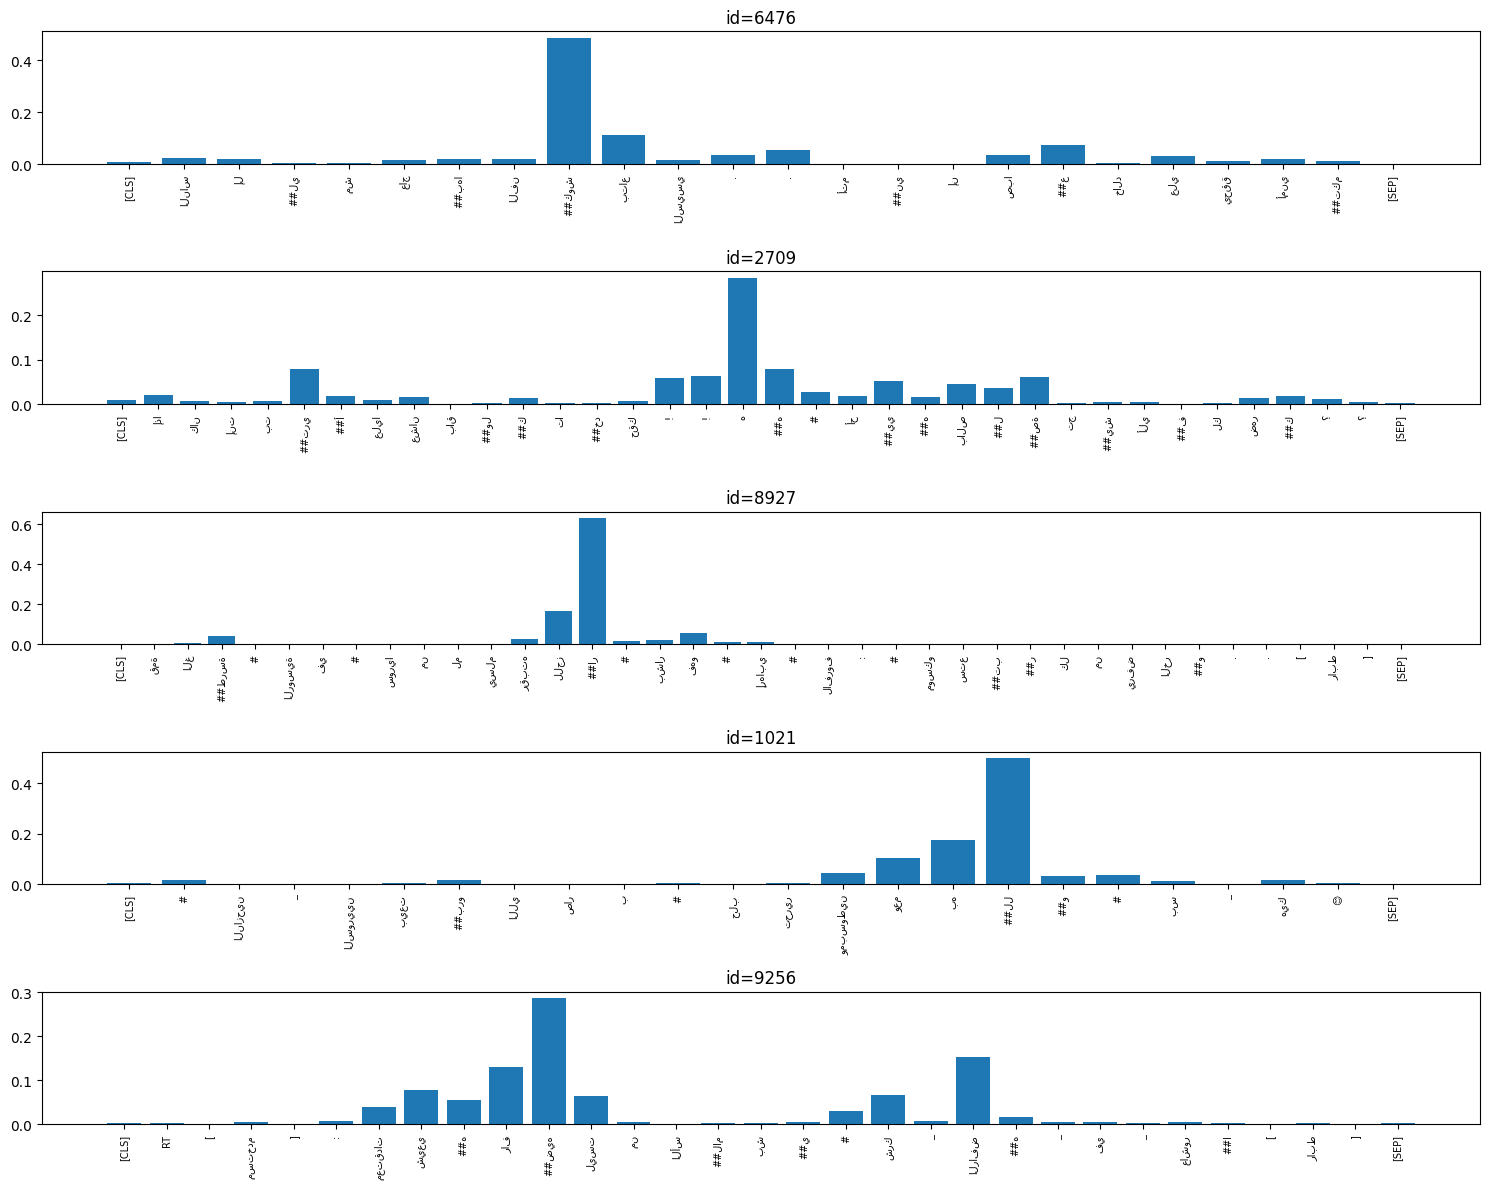

In [19]:
class FrozenAttentionHead(nn.Module):
    def __init__(self,hidden):
        super().__init__()
        self.lstm=nn.LSTM(hidden,128,bidirectional=True,batch_first=True)
        self.pool=AttentionPool(256)
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(256,2))
    def forward(self,states,mask,return_attention=False):
        h,_=self.lstm(states); pooled,a=self.pool(h,mask.bool())
        logits=self.head(pooled)
        return (logits,a) if return_attention else logits

def frozen_batches(tok,enc,frame,batch_size=32):
    texts=frame.tweet.map(lambda t:plm_preprocess(t,ARABERT)).tolist()
    for i in range(0,len(texts),batch_size):
        batch=encode_texts(tok,texts[i:i+batch_size]).to(dev)
        with torch.no_grad(): states=enc(**batch).last_hidden_state
        labels=torch.tensor(frame.sarcasm.astype(int).iloc[i:i+batch_size].to_numpy(),device=dev)
        yield states,batch['attention_mask'],labels

def frozen_head_scores(tok,enc,head,frame):
    head.eval(); ans=[]
    with torch.inference_mode():
        for states,mask,_ in frozen_batches(tok,enc,frame):
            ans.extend(head(states,mask).softmax(-1)[:,1].cpu().numpy())
    return np.asarray(ans)

if RUN_FROZEN:
    for p in d_enc.parameters(): p.requires_grad_(False)
    d_enc.eval(); head=FrozenAttentionHead(d_enc.config.hidden_size).to(dev)
    opt=torch.optim.AdamW(head.parameters(),lr=1e-3)
    best=-1;state=None;patience=0;st=time.perf_counter()
    for epoch in range(EPOCHS_STATIC):
        head.train()
        shuffled=train_model.sample(frac=1,random_state=SEED+epoch)
        for states,mask,labels in frozen_batches(d_tok,d_enc,shuffled):
            opt.zero_grad(); loss=nn.functional.cross_entropy(head(states,mask),labels)
            loss.backward();opt.step()
        score=frozen_head_scores(d_tok,d_enc,head,val)
        f1=metrics(y_val,score,best_threshold(y_val,score))['f1_sarc']
        print('D2 epoch',epoch+1,'F1',round(f1,4))
        if f1>best+1e-4:
            best=f1;state={k:v.detach().cpu().clone() for k,v in head.state_dict().items()};patience=0
        else:patience+=1
        if patience>=2:break
    head.load_state_dict(state);MODELS['D2_attention']=(d_tok,d_enc,head)
    torch.save(state,ROOT/'models'/'D2_attention.pt')
    log_result('D2_attention','D2','plm_minimal',frozen_head_scores(d_tok,d_enc,head,val),
               time.perf_counter()-st,sum(p.numel() for p in head.parameters()))
    # Visualiser cinq tweets sarcastiques de val, sans regarder le test.
    samples=val.loc[val.sarcasm].head(5)
    fig,axes=plt.subplots(5,1,figsize=(15,12))
    for ax,(_,row) in zip(axes,samples.iterrows()):
        batch=encode_texts(d_tok,[plm_preprocess(row.tweet,ARABERT)]).to(dev)
        with torch.inference_mode():
            h=d_enc(**batch).last_hidden_state;_,weights=head(h,batch['attention_mask'],True)
        ids=batch['input_ids'][0].cpu().tolist(); toks=d_tok.convert_ids_to_tokens(ids)
        n=int(batch['attention_mask'][0].sum())
        ax.bar(range(n),weights[0,:n].cpu().numpy())
        ax.set_xticks(range(n),toks[:n],rotation=90,fontsize=7)
        ax.set_title(f'id={row.id}')
    plt.tight_layout();plt.savefig(ROOT/'figures'/'D2_attention_5.png',dpi=180);plt.show()
else: print('D2 ignoré : RUN_FROZEN=False')

## E. Fine-tuning mono-tâche et multi-tâche

In [20]:
from transformers import get_linear_schedule_with_warmup
SENT_MAP={'NEG':0,'NEU':1,'POS':2}

class PLMDataset(Dataset):
    def __init__(self,frame,tok,remove_url_mention=False):
        texts=frame.tweet.map(lambda t:plm_preprocess(t,tok.name_or_path,remove_url_mention)).tolist()
        limit=64 if 'arabertv02-twitter' in tok.name_or_path else MAX_LEN
        self.tokens=tok(texts,truncation=True,padding='max_length',max_length=limit,
                        return_tensors='pt')
        self.y=torch.tensor(frame.sarcasm.astype(int).to_numpy(),dtype=torch.long)
        self.sent=torch.tensor(frame.sentiment.map(SENT_MAP).to_numpy(),dtype=torch.long)
    def __len__(self):return len(self.y)
    def __getitem__(self,i):
        return {**{k:v[i] for k,v in self.tokens.items()},'labels':self.y[i],
                'sentiment':self.sent[i]}

class MultiTask(nn.Module):
    def __init__(self,name,multi=False):
        super().__init__();self.enc=AutoModel.from_pretrained(name)
        h=self.enc.config.hidden_size
        self.dropout=nn.Dropout(.1)
        self.sarc=nn.Linear(h,2)
        self.sent=nn.Linear(h,3) if multi else None
    def forward(self,input_ids,attention_mask,token_type_ids=None):
        kw={'input_ids':input_ids,'attention_mask':attention_mask}
        if token_type_ids is not None:kw['token_type_ids']=token_type_ids
        cls=self.dropout(self.enc(**kw).last_hidden_state[:,0])
        return self.sarc(cls),self.sent(cls) if self.sent is not None else None

def plm_scores(model,loader):
    model.eval(); scores=[]
    with torch.inference_mode():
        for batch in loader:
            kw={k:v.to(dev) for k,v in batch.items() if k in ['input_ids','attention_mask','token_type_ids']}
            logits,_=model(**kw)
            scores.extend(logits.softmax(-1)[:,1].cpu().numpy())
    return np.asarray(scores)

def train_plm(name,base_name,multi=False,lam=0.5,seed=SEED,
              tr_frame=None,va_frame=None,remove_url_mention=False,epochs=EPOCHS_PLM):
    seed_everything(seed)
    tr_frame=train_model if tr_frame is None else tr_frame
    va_frame=val if va_frame is None else va_frame
    tok=AutoTokenizer.from_pretrained(base_name)
    train_ds=PLMDataset(tr_frame,tok,remove_url_mention)
    val_dl=DataLoader(PLMDataset(va_frame,tok,remove_url_mention),batch_size=32)
    train_dl=DataLoader(train_ds,batch_size=BATCH_PLM,shuffle=True)
    model=MultiTask(base_name,multi).to(dev)
    yy=tr_frame.sarcasm.astype(int).to_numpy(); n=np.bincount(yy,minlength=2)
    weights=torch.tensor([len(yy)/(2*n[0]),len(yy)/(2*n[1])],device=dev,dtype=torch.float32)
    ce_sarc=nn.CrossEntropyLoss(weight=weights)
    opt=torch.optim.AdamW(model.parameters(),lr=2e-5,weight_decay=.01)
    steps=math.ceil(len(train_dl)/ACCUM_STEPS)*epochs
    sched=get_linear_schedule_with_warmup(opt,int(.1*steps),steps)
    scaler=torch.amp.GradScaler('cuda',enabled=dev.type=='cuda')
    best=-1;state=None;patience=0;st=time.perf_counter()
    yva=va_frame.sarcasm.astype(int).to_numpy()
    for epoch in range(epochs):
        model.train();opt.zero_grad(set_to_none=True)
        for step,batch in enumerate(train_dl):
            kw={k:v.to(dev) for k,v in batch.items() if k in ['input_ids','attention_mask','token_type_ids']}
            with torch.autocast(device_type=dev.type,dtype=torch.float16 if dev.type=='cuda' else torch.bfloat16,
                                enabled=dev.type=='cuda'):
                sarc,sent=model(**kw)
                loss=ce_sarc(sarc,batch['labels'].to(dev))
                if multi:loss=loss+lam*nn.functional.cross_entropy(sent,batch['sentiment'].to(dev))
                loss=loss/ACCUM_STEPS
            scaler.scale(loss).backward()
            if (step+1)%ACCUM_STEPS==0 or step+1==len(train_dl):
                scaler.unscale_(opt);nn.utils.clip_grad_norm_(model.parameters(),1)
                scaler.step(opt);scaler.update();sched.step();opt.zero_grad(set_to_none=True)
        score=plm_scores(model,val_dl)
        f1=metrics(yva,score,best_threshold(yva,score))['f1_sarc']
        print(name,'epoch',epoch+1,'val F1',round(f1,4))
        if f1>best+1e-4:
            best=f1;patience=0
            state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:patience+=1
        if patience>=2:break
    model.load_state_dict(state)
    score=plm_scores(model,val_dl)
    ckpt={'base_name':base_name,'multi':multi,'lam':lam,'seed':seed,
          'remove_url_mention':remove_url_mention,'state':state}
    torch.save(ckpt,ROOT/'models'/f'{name}.pt')
    MODELS[name]=(tok,model,remove_url_mention)
    if va_frame is val:
        log_result(name,'E2' if multi else 'E1','plm_minimal'+('_sans_url_mention' if remove_url_mention else ''),
                   score,time.perf_counter()-st,sum(p.numel() for p in model.parameters() if p.requires_grad),seed)
    return tok,model,score,time.perf_counter()-st

def load_plm_checkpoint(name):
    ckpt=torch.load(ROOT/'models'/f'{name}.pt',map_location='cpu',weights_only=False)
    tok=AutoTokenizer.from_pretrained(ckpt['base_name'])
    model=MultiTask(ckpt['base_name'],ckpt['multi']).to(dev)
    model.load_state_dict(ckpt['state']);model.eval()
    return tok,model,ckpt['remove_url_mention']

def plm_frame_scores(bundle,frame):
    tok,model,remove=bundle
    loader=DataLoader(PLMDataset(frame,tok,remove),batch_size=32)
    return plm_scores(model,loader)

In [21]:
if RUN_FINETUNE:
    for base in PLM_NAMES:
        slug='arabert' if 'arabert' in base else 'marbert'
        train_plm(f'E1_{slug}_seed42',base,multi=False)
        for lam in [.3,.5,1.0]:
            train_plm(f'E2_{slug}_lam{lam}_seed42',base,multi=True,lam=lam)
    # Sélection sur val uniquement ; les deux familles finales sont réentraînées avec 3 graines.
    best_e1=max((r for r in RESULTS if r['family']=='E1'),key=lambda r:r['val_f1_sarc'])
    best_e2=max((r for r in RESULTS if r['family']=='E2'),key=lambda r:r['val_f1_sarc'])
    print('Sélection E1/E2 :',best_e1['model'],best_e2['model'])
    for selected in [best_e1,best_e2]:
        base=PLM_NAMES[0] if 'arabert' in selected['model'] else PLM_NAMES[1]
        lam=float(re.search(r'lam([0-9.]+)_seed',selected['model']).group(1)) if selected['family']=='E2' else .5
        prefix=selected['model'].replace('_seed42','')
        for seed in FINAL_SEEDS[1:]:
            train_plm(f'{prefix}_seed{seed}',base,multi=selected['family']=='E2',lam=lam,seed=seed)
else: print('Partie E ignorée : RUN_FINETUNE=False')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_525/346452310.py:71: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and la

E1_arabert_seed42 epoch 1 val F1 0.6544
E1_arabert_seed42 epoch 2 val F1 0.6747
E1_arabert_seed42 epoch 3 val F1 0.657
E1_arabert_seed42 epoch 4 val F1 0.6627
E1_arabert_seed42 {'val_f1_sarc': 0.6747, 'val_pr_auc': np.float64(0.7103), 'threshold': 0.86}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_525/346452310.py:71: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and la

...

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_525/346452310.py:71: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and la

E2_arabert_lam0.3_seed123 epoch 1 val F1 0.7059
E2_arabert_lam0.3_seed123 epoch 2 val F1 0.6941
E2_arabert_lam0.3_seed123 epoch 3 val F1 0.6898
E2_arabert_lam0.3_seed123 {'val_f1_sarc': 0.7059, 'val_pr_auc': np.float64(0.7349), 'threshold': 0.76}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_525/346452310.py:71: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and la

E2_arabert_lam0.3_seed2025 epoch 1 val F1 0.6748
E2_arabert_lam0.3_seed2025 epoch 2 val F1 0.6694
E2_arabert_lam0.3_seed2025 epoch 3 val F1 0.6802
E2_arabert_lam0.3_seed2025 epoch 4 val F1 0.6849
E2_arabert_lam0.3_seed2025 {'val_f1_sarc': 0.6849, 'val_pr_auc': np.float64(0.7011), 'threshold': 0.74}


## Sauvegarde des résultats Colab

**Exécuter cette cellule après E et avant F.** Les calculs précédents ont enregistré leurs fichiers dans `/content` sur la machine Colab, et non dans le dossier Windows. Cette cellule copie les résultats, données et modèles finaux vers Google Drive, puis place les sorties des sections F et G dans ce dossier persistant. L'autorisation Google Drive peut être demandée.

In [ ]:
from google.colab import drive
import shutil
drive.mount('/content/drive')

source_root = Path('/content') if (Path('/content') / 'results' / 'results.csv').exists() else ROOT
drive_root = Path('/content/drive/MyDrive/TP2_Sarcasme')
drive_root.mkdir(parents=True, exist_ok=True)

for dirname in ['data', 'results', 'predictions', 'figures']:
    src = source_root / dirname
    if src.exists():
        shutil.copytree(src, drive_root / dirname, dirs_exist_ok=True)

model_files = ['A_tfidf.joblib']
if RUN_STATIC:
    model_files.append(f'{best_c}.pt')
if RUN_FROZEN:
    best_d_for_save = max((r for r in RESULTS if r['family'] in {'D1', 'D2'}),
                          key=lambda r: r['val_f1_sarc'])['model']
    model_files.append('D2_attention.pt' if best_d_for_save == 'D2_attention'
                       else f'{best_d_for_save}_lr.joblib')
if RUN_FINETUNE:
    for selected in [best_e1, best_e2]:
        prefix = selected['model'].replace('_seed42', '')
        model_files.extend(f'{prefix}_seed{seed}.pt' for seed in FINAL_SEEDS)

(drive_root / 'models').mkdir(exist_ok=True)
for filename in model_files:
    src = source_root / 'models' / filename
    if src.exists():
        shutil.copy2(src, drive_root / 'models' / filename)
    else:
        print('Fichier absent :', src)

ROOT = drive_root
print('Sorties futures :', ROOT)
print('Résultats copiés :', (ROOT / 'results' / 'results.csv').exists())
print('Modèles copiés :', len(list((ROOT / 'models').glob('*'))))

print('Vérification des fichiers dans Drive :')
for dirname in ['data', 'results', 'predictions', 'figures', 'models']:
    folder = ROOT / dirname
    files = [p for p in folder.rglob('*') if p.is_file()] if folder.exists() else []
    total_mb = sum(p.stat().st_size for p in files) / 1e6
    print(f'{dirname}: {len(files)} fichiers, {total_mb:.1f} Mo')
    for p in files[:5]:
        print('  ', p.relative_to(ROOT))


## F. Généralisation — ouverture du test officiel

À partir de cette cellule seulement, les étiquettes du test sont utilisées. **Ne pas modifier les seuils ou les modèles après avoir vu les scores test.** Les courbes de seuil test sont descriptives, a posteriori.

In [22]:
if RUN_GENERALIZATION:
    test=test_raw.copy()
    y_test=test.sarcasm.astype(int).to_numpy()
    print('Taux test :',test.sarcasm.mean(),'vs val :',val.sarcasm.mean())
    display(rate_table(test));display(test.groupby('sentiment').sarcasm.agg(['size','mean']))
    print('Tweets magreb train/test :',int((train_model.dialect=='magreb').sum()),
          int((test.dialect=='magreb').sum()))
    print('OOV test :',oov_rate(test))
    print('Corrélation de l\'artefact sur test, pour analyse uniquement :')
    display(pd.DataFrame({'n':test_flags.sum(),
        'taux_sarcasme_avec':[test.loc[test_flags[k],'sarcasm'].mean() for k in test_flags]}))

    def baseline_frame_scores(name,frame):
        fe,lr=MODELS[name]
        remove_cues=name.endswith('sans_indices')
        texts=frame.tweet.map(lambda t:preprocess(t,'tfidf',remove_cues=remove_cues))
        return lr.predict_proba(fe.transform(texts))[:,1]
    TEST_SCORES['A_tfidf']=baseline_frame_scores('A_tfidf',test)
    if RUN_STATIC:
        TEST_SCORES[best_c]=word_scores(MODELS[best_c],test)
    if RUN_FROZEN:
        best_d=max((r for r in RESULTS if r['family'] in {'D1','D2'}),key=lambda r:r['val_f1_sarc'])['model']
        if best_d.startswith('D1'):
            tok,enc,lr,pool=MODELS[best_d]
            X=frozen_features(tok,enc,test.tweet.map(lambda t:plm_preprocess(t,ARABERT)).tolist(),pool)
            TEST_SCORES[best_d]=lr.predict_proba(X)[:,1]
        else:
            tok,enc,head=MODELS[best_d]
            TEST_SCORES[best_d]=frozen_head_scores(tok,enc,head,test)
    if RUN_FINETUNE:
        for selected in [best_e1,best_e2]:
            name=selected['model']
            prefix=name.replace('_seed42','')
            for seed in FINAL_SEEDS:
                this_name=f'{prefix}_seed{seed}'
                bundle=MODELS.get(this_name) or load_plm_checkpoint(this_name)
                TEST_SCORES[this_name]=plm_frame_scores(bundle,test)
    for name,score in TEST_SCORES.items():
        threshold=THRESH[name]
        vals=metrics(y_test,score,threshold)
        row=next(r for r in RESULTS if r['model']==name)
        row.update({'test_'+k:v for k,v in vals.items()})
        pd.DataFrame({'id':test.id,'y_true':y_test,'y_pred':(score>=threshold).astype(int),
                      'proba_sarcasme':score,'proba_non_sarcasme':1-score}).to_csv(
                          ROOT/'predictions'/f'{name}.csv',index=False)
    pd.DataFrame(RESULTS).to_csv(ROOT/'results'/'results.csv',index=False)
    display(pd.DataFrame(RESULTS).dropna(subset=['test_f1_sarc']).sort_values('test_f1_sarc',ascending=False))
else:print('Test toujours scellé : RUN_GENERALIZATION=False')

Taux test : 0.27366666666666667 vs val : 0.17290836653386454


,size,taux_sarcasme
dialect,,
egypt,306,0.506536
gulf,322,0.177019
levant,47,0.297872
magreb,2,0.000000
msa,2323,0.256134


,size,mean
sentiment,,
NEG,1677,0.422779
NEU,748,0.141711
POS,575,0.010435


Tweets magreb train/test : 35 2
OOV test : 0.27081560106143293
Corrélation de l'artefact sur test, pour analyse uniquement :


,n,taux_sarcasme_avec
url,440,0.036364
mention,19,0.000000
hashtag,960,0.391667
emoji,488,0.061475
rire,96,0.562500
ponctuation_repetee,826,0.388620
diacritiques,587,0.241908
tatweel,219,0.515982
lettres_repetees,382,0.342932
latin,718,0.119777


,model,family,preprocess,seed,threshold,train_seconds,trainable_params,val_f1_sarc,val_macro_f1,val_pr_auc,val_precision,val_recall,val_accuracy,test_f1_sarc,test_macro_f1,test_pr_auc,test_precision,test_recall,test_accuracy
31,E1_marbert_seed2025,E1,plm_minimal,2025,0.61,296.430599,162842882,0.657040,0.779951,0.688817,0.540059,0.838710,0.848606,0.641528,0.728293,0.649710,0.536446,0.797808,0.756000
26,E1_marbert_seed42,E1,plm_minimal,42,0.86,297.368823,162842882,0.687225,0.809079,0.692069,0.658228,0.718894,0.886853,0.624018,0.732587,0.639894,0.578564,0.677223,0.776667
30,E1_marbert_seed123,E1,plm_minimal,123,0.74,391.987832,162842882,0.663736,0.794642,0.705419,0.634454,0.695853,0.878088,0.620489,0.734112,0.640075,0.594203,0.649208,0.782667
23,E2_arabert_lam0.3_seed42,E2,plm_minimal,42,0.56,185.892691,135197189,0.701595,0.819170,0.724697,0.693694,0.709677,0.895618,0.609639,0.730165,0.651682,0.603099,0.616322,0.784000
32,E2_arabert_lam0.3_seed123,E2,plm_minimal,123,0.76,186.034159,135197189,0.705882,0.820030,0.734891,0.669421,0.746544,0.892430,0.600122,0.725296,0.649833,0.603448,0.596833,0.782333
33,E2_arabert_lam0.3_seed2025,E2,plm_minimal,2025,0.74,245.065089,135197189,0.684932,0.809165,0.701092,0.678733,0.691244,0.890040,0.592593,0.722663,0.633254,0.611399,0.574909,0.783667
21,D2_attention,D2,plm_minimal,42,0.35,171.260255,986114,0.686364,0.809848,0.719944,0.677130,0.695853,0.890040,0.585000,0.717045,0.628037,0.600770,0.570037,0.778667
15,C_aravec_degele_transformer,C,static,42,0.28,8.720825,1780246,0.563265,0.728662,0.544749,0.505495,0.635945,0.829482,0.554776,0.677919,0.553813,0.498062,0.626066,0.725000
0,A_tfidf,A,tfidf,42,0.54,5.322962,205145,0.526807,0.714629,0.517040,0.533019,0.520737,0.838247,0.519093,0.666346,0.533128,0.508772,0.529842,0.731333


A_tfidf seuil val 0.54 seuil optimal test a posteriori 0.48000000000000004
C_aravec_degele_transformer seuil val 0.28 seuil optimal test a posteriori 0.18000000000000002
D2_attention seuil val 0.35000000000000003 seuil optimal test a posteriori 0.24000000000000002
E1_marbert_seed42 seuil val 0.86 seuil optimal test a posteriori 0.75
E1_marbert_seed123 seuil val 0.74 seuil optimal test a posteriori 0.5800000000000001
E1_marbert_seed2025 seuil val 0.61 seuil optimal test a posteriori 0.53
E2_arabert_lam0.3_seed42 seuil val 0.56 seuil optimal test a posteriori 0.44
E2_arabert_lam0.3_seed123 seuil val 0.76 seuil optimal test a posteriori 0.64
E2_arabert_lam0.3_seed2025 seuil val 0.74 seuil optimal test a posteriori 0.21000000000000002


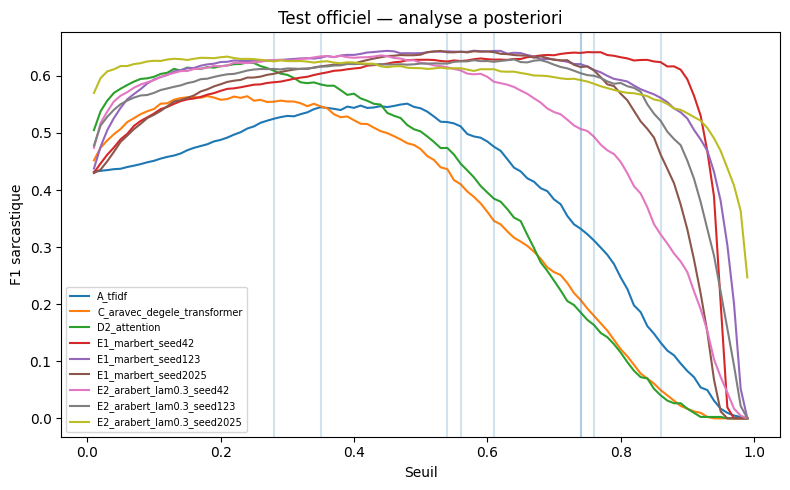

,model,url,n,f1_sarc
0,A_tfidf,False,2560,0.525742
1,A_tfidf,True,440,0.080000
2,C_aravec_degele_transformer,False,2560,0.561365
3,C_aravec_degele_transformer,True,440,0.222222
4,D2_attention,False,2560,0.592498
5,D2_attention,True,440,0.148148
6,E1_marbert_seed42,False,2560,0.631339
7,E1_marbert_seed42,True,440,0.148148
8,E1_marbert_seed123,False,2560,0.629254
9,E1_marbert_seed123,True,440,0.279070


,model,vrais_positifs_avant,rappel_apres_ablation,chute_rappel
0,A_tfidf,435,0.905747,0.094253
1,C_aravec_degele_transformer,514,0.941634,0.058366
2,D2_attention,468,0.931624,0.068376
3,E1_marbert_seed42,556,0.937050,0.062950
4,E1_marbert_seed123,533,0.919325,0.080675
5,E1_marbert_seed2025,655,0.966412,0.033588
6,E2_arabert_lam0.3_seed42,506,0.942688,0.057312
7,E2_arabert_lam0.3_seed123,490,0.953061,0.046939
8,E2_arabert_lam0.3_seed2025,472,0.936441,0.063559


In [23]:
if RUN_GENERALIZATION:
    # F1 : prior shift et courbes a posteriori, non utilisées pour choisir le seuil.
    fig,ax=plt.subplots(figsize=(8,5))
    for name in TEST_SCORES:
        score=TEST_SCORES[name]
        curve=[f1_score(y_test,score>=t,zero_division=0) for t in THRESHOLDS]
        ax.plot(THRESHOLDS,curve,label=name)
        ax.axvline(THRESH[name],alpha=.2)
        print(name,'seuil val',THRESH[name],'seuil optimal test a posteriori',
              float(THRESHOLDS[np.argmax(curve)]))
    ax.set(xlabel='Seuil',ylabel='F1 sarcastique',title='Test officiel — analyse a posteriori')
    ax.legend(fontsize=7);plt.tight_layout()
    plt.savefig(ROOT/'figures'/'F1_seuil_test.png',dpi=180);plt.show()

    # F3 : sous-groupes avec / sans URL, pour chaque modèle final.
    rows=[]
    for name,score in TEST_SCORES.items():
        for present in [False,True]:
            ix=test_flags.url.to_numpy()==present
            rows.append({'model':name,'url':present,'n':int(ix.sum()),
                         'f1_sarc':f1_score(y_test[ix],score[ix]>=THRESH[name],zero_division=0)})
    display(pd.DataFrame(rows))

    # F4 : suppression des indices uniquement sur les vrais positifs.
    cue_rows=[]
    for name,score in TEST_SCORES.items():
        ix=np.flatnonzero((y_test==1)&(score>=THRESH[name]))
        subset=test.iloc[ix].copy()
        if not len(subset): continue
        subset['tweet']=subset.tweet.map(lambda t:preprocess(t,'plm',remove_cues=True))
        if name.startswith('A_'): altered=baseline_frame_scores(name,subset)
        elif name.startswith('C_'): altered=word_scores(MODELS[name],subset)
        elif name.startswith('D1_'):
            tok,enc,lr,pool=MODELS[name]
            altered=lr.predict_proba(frozen_features(tok,enc,
                subset.tweet.map(lambda t:plm_preprocess(t,ARABERT)).tolist(),pool))[:,1]
        elif name=='D2_attention':
            tok,enc,head=MODELS[name];altered=frozen_head_scores(tok,enc,head,subset)
        else: altered=plm_frame_scores(MODELS.get(name) or load_plm_checkpoint(name),subset)
        cue_rows.append({'model':name,'vrais_positifs_avant':len(ix),
                         'rappel_apres_ablation':float((altered>=THRESH[name]).mean()),
                         'chute_rappel':1-float((altered>=THRESH[name]).mean())})
    display(pd.DataFrame(cue_rows))

In [24]:
if RUN_GENERALIZATION:
    # F3 : réentraîner réellement la baseline sans URL et mentions.
    fit_tfidf(train_model,val,remove_url_mention=True,name='A_tfidf_sans_url_mention')
    score=baseline_frame_scores('A_tfidf_sans_url_mention',test)
    TEST_SCORES['A_tfidf_sans_url_mention']=score
    row=next(r for r in RESULTS if r['model']=='A_tfidf_sans_url_mention')
    row.update({'test_'+k:v for k,v in metrics(y_test,score,THRESH['A_tfidf_sans_url_mention']).items()})
    pd.DataFrame({'id':test.id,'y_true':y_test,'y_pred':(score>=THRESH['A_tfidf_sans_url_mention']).astype(int),
                  'proba_sarcasme':score,'proba_non_sarcasme':1-score}).to_csv(
                      ROOT/'predictions'/'A_tfidf_sans_url_mention.csv',index=False)
    if RUN_FINETUNE:
        # Meilleur E sur val, même architecture et seuil recalculé uniquement sur val.
        best_e=max([best_e1,best_e2],key=lambda r:r['val_f1_sarc'])
        base=PLM_NAMES[0] if 'arabert' in best_e['model'] else PLM_NAMES[1]
        lam=float(re.search(r'lam([0-9.]+)_seed',best_e['model']).group(1)) if best_e['family']=='E2' else .5
        name='F3_E_sans_url_mention'
        bundle=train_plm(name,base,multi=best_e['family']=='E2',lam=lam,remove_url_mention=True)
        score=plm_frame_scores(MODELS[name],test);TEST_SCORES[name]=score
        row=next(r for r in RESULTS if r['model']==name)
        row.update({'test_'+k:v for k,v in metrics(y_test,score,THRESH[name]).items()})
        pd.DataFrame({'id':test.id,'y_true':y_test,'y_pred':(score>=THRESH[name]).astype(int),
                      'proba_sarcasme':score,'proba_non_sarcasme':1-score}).to_csv(
                          ROOT/'predictions'/f'{name}.csv',index=False)
    pd.DataFrame(RESULTS).to_csv(ROOT/'results'/'results.csv',index=False)
else: print('F3 ignoré')

A_tfidf_sans_url_mention {'val_f1_sarc': 0.5017, 'val_pr_auc': np.float64(0.5096), 'threshold': 0.4}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


F3_E_sans_url_mention epoch 1 val F1 0.6909
F3_E_sans_url_mention epoch 2 val F1 0.6874
F3_E_sans_url_mention epoch 3 val F1 0.6706
F3_E_sans_url_mention {'val_f1_sarc': 0.6909, 'val_pr_auc': np.float64(0.7245), 'threshold': 0.61}


In [25]:
if RUN_GENERALIZATION and RUN_FINETUNE:
    # F2 : dialecte egypt non vu. Le seuil vient de val, excluant egypt pour cette expérience.
    train_no_egypt=train_model.loc[train_model.dialect!='egypt'].copy()
    val_no_egypt=val.loc[val.dialect!='egypt'].copy()
    egypt_test=test.loc[test.dialect=='egypt'].copy()
    best_e=max([best_e1,best_e2],key=lambda r:r['val_f1_sarc'])
    base=PLM_NAMES[0] if 'arabert' in best_e['model'] else PLM_NAMES[1]
    lam=float(re.search(r'lam([0-9.]+)_seed',best_e['model']).group(1)) if best_e['family']=='E2' else .5
    name='F2_E_sans_egypt'
    tok,model,val_score,_=train_plm(name,base,multi=best_e['family']=='E2',lam=lam,
                                     tr_frame=train_no_egypt,va_frame=val_no_egypt)
    threshold=best_threshold(val_no_egypt.sarcasm.astype(int).to_numpy(),val_score)
    score_excl=plm_frame_scores((tok,model,False),egypt_test)
    score_full=plm_frame_scores(MODELS.get(best_e['model']) or load_plm_checkpoint(best_e['model']),egypt_test)
    yt=egypt_test.sarcasm.astype(int).to_numpy()
    display(pd.DataFrame([
        {'entrainement':'sans egypt','n_test_egypt':len(yt),'f1':f1_score(yt,score_excl>=threshold,zero_division=0)},
        {'entrainement':'tous dialectes','n_test_egypt':len(yt),'f1':f1_score(yt,score_full>=THRESH[best_e['model']],zero_division=0)}]))
else:print('F2 demande RUN_GENERALIZATION=True et RUN_FINETUNE=True')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_525/346452310.py:71: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and la

F2_E_sans_egypt epoch 1 val F1 0.6134
F2_E_sans_egypt epoch 2 val F1 0.6148
F2_E_sans_egypt epoch 3 val F1 0.64
F2_E_sans_egypt epoch 4 val F1 0.6385


,entrainement,n_test_egypt,f1
0,sans egypt,306,0.740984
1,tous dialectes,306,0.776119


In [26]:
from scipy.stats import binomtest
def bootstrap_f1_ci(y,score,threshold,B=1000,seed=SEED):
    rng=np.random.default_rng(seed);n=len(y);v=[]
    for _ in range(B):
        ix=rng.integers(0,n,n)
        v.append(f1_score(np.asarray(y)[ix],np.asarray(score)[ix]>=threshold,zero_division=0))
    return np.quantile(v,[.025,.975])

def mcnemar_exact(y,pred_a,pred_b):
    a=np.asarray(pred_a)==np.asarray(y);b=np.asarray(pred_b)==np.asarray(y)
    n01=int((a&~b).sum());n10=int((~a&b).sum())
    return {'A_seul_correct':n01,'B_seul_correct':n10,
            'p_exact':binomtest(min(n01,n10),n01+n10,.5).pvalue if n01+n10 else 1.0}

if RUN_GENERALIZATION:
    rows=[]
    for name,score in TEST_SCORES.items():
        ci=bootstrap_f1_ci(y_test,score,THRESH[name])
        rows.append({'model':name,'f1_test':metrics(y_test,score,THRESH[name])['f1_sarc'],
                     'IC95_bas':ci[0],'IC95_haut':ci[1]})
    display(pd.DataFrame(rows).sort_values('f1_test',ascending=False))
    ranked=sorted(TEST_SCORES,key=lambda n:metrics(y_val,VAL_SCORES[n],THRESH[n])['f1_sarc'],reverse=True)
    print('McNemar entre deux meilleurs modèles :',ranked[:2],
          mcnemar_exact(y_test,TEST_SCORES[ranked[0]]>=THRESH[ranked[0]],
                        TEST_SCORES[ranked[1]]>=THRESH[ranked[1]]))
    if RUN_FINETUNE:
        for selected in [best_e1,best_e2]:
            prefix=selected['model'].replace('_seed42','')
            vals=[metrics(y_test,TEST_SCORES[f'{prefix}_seed{s}'],THRESH[f'{prefix}_seed{s}'])['f1_sarc'] for s in FINAL_SEEDS]
            print(prefix,'3 graines, F1 moyenne ± écart-type :',np.mean(vals),np.std(vals,ddof=1))

,model,f1_test,IC95_bas,IC95_haut
5,E1_marbert_seed2025,0.641528,0.616468,0.664763
3,E1_marbert_seed42,0.624018,0.597941,0.650596
4,E1_marbert_seed123,0.620489,0.592805,0.645869
6,E2_arabert_lam0.3_seed42,0.609639,0.582568,0.639570
10,F3_E_sans_url_mention,0.606024,0.579688,0.634710
7,E2_arabert_lam0.3_seed123,0.600122,0.574073,0.627944
8,E2_arabert_lam0.3_seed2025,0.592593,0.562878,0.623105
2,D2_attention,0.585000,0.554925,0.612994
1,C_aravec_degele_transformer,0.554776,0.526670,0.581235
9,A_tfidf_sans_url_mention,0.534873,0.507999,0.560800


McNemar entre deux meilleurs modèles : ['E2_arabert_lam0.3_seed123', 'E2_arabert_lam0.3_seed42'] {'A_seul_correct': 109, 'B_seul_correct': 114, 'p_exact': np.float64(0.7888792496368072)}
E1_marbert 3 graines, F1 moyenne ± écart-type : 0.6286782705966396 0.011267141953041853
E2_arabert_lam0.3 3 graines, F1 moyenne ± écart-type : 0.6007845402612468 0.008542245064988291


### F6 — Analyse qualitative des erreurs

Les 30 tweets ci-dessous sont sélectionnés automatiquement, mais **la catégorie doit être décidée manuellement** à partir du contexte. Renseigner la colonne `categorie_manuelle` dans le CSV généré (contexte/connaissance, ironie sans marqueur, marqueur mal interprété, dialecte, bruit d'annotation). Ne pas appeler « bruit d'annotation » un désaccord entre le modèle et l'étiquette sans vérification humaine.

In [27]:
if RUN_GENERALIZATION:
    selected=max(VAL_SCORES,key=lambda n:metrics(y_val,VAL_SCORES[n],THRESH[n])['f1_sarc']
                 if n in TEST_SCORES else -1)
    pred=(TEST_SCORES[selected]>=THRESH[selected]).astype(int)
    fn=test.loc[(y_test==1)&(pred==0),['id','tweet','dialect','sarcasm','key']].head(15).copy()
    fp=test.loc[(y_test==0)&(pred==1),['id','tweet','dialect','sarcasm','key']].head(15).copy()
    fn['erreur']='FN';fp['erreur']='FP'
    errors=pd.concat([fn,fp],ignore_index=True)
    errors['collision_contradictoire_train']=errors.key.isin(set(contradictory_keys))
    errors['categorie_manuelle']='A_COMPLETER'
    path=ROOT/'results'/'F6_30_erreurs_a_annoter.csv'
    errors.to_csv(path,index=False)
    print('Modèle :',selected,'— fichier :',path)
    display(errors.drop(columns='key'))

Modèle : E2_arabert_lam0.3_seed123 — fichier : /content/results/F6_30_erreurs_a_annoter.csv


,id,tweet,dialect,sarcasm,erreur,collision_contradictoire_train,categorie_manuelle
0,1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,msa,True,FN,False,A_COMPLETER
1,4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...,msa,True,FN,False,A_COMPLETER
2,7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراس...,msa,True,FN,False,A_COMPLETER
3,12,إدارة #الاتحاد تطلب من الداهية الروماني بيتورك...,gulf,True,FN,False,A_COMPLETER
4,14,العريضي 3 اعراس لابنو 3 فساتين للعروس ضيافة صل...,msa,True,FN,False,A_COMPLETER
5,18,الأمير: الوووو مين؟ الكوتش:أنا سامي الجابر الأ...,gulf,True,FN,False,A_COMPLETER
6,42,يمكن يبغون تزيد خبرتهم في شراء التذاكر للمستقب...,gulf,True,FN,False,A_COMPLETER
7,48,تأمل الشخصيات اللي هتقود المشهد في مصر تعرف اح...,msa,True,FN,False,A_COMPLETER
8,57,مصحبش فارافير 💪 https://t.co/DQFB5QIi8q,msa,True,FN,False,A_COMPLETER
9,73,مدحت شلبي : وادي حسام غالي و عبدالله السعيد فـ...,egypt,True,FN,False,A_COMPLETER


## G. Comparaison finale, matrice de confusion et compte-rendu

,model,family,val_f1_sarc,test_f1_sarc,test_pr_auc,train_seconds,trainable_params,threshold
32,E2_arabert_lam0.3_seed123,E2,0.705882,0.600122,0.649833,186.034159,135197189,0.76
23,E2_arabert_lam0.3_seed42,E2,0.701595,0.609639,0.651682,185.892691,135197189,0.56
35,F3_E_sans_url_mention,E2,0.690909,0.606024,0.649507,184.921838,135197189,0.61
26,E1_marbert_seed42,E1,0.687225,0.624018,0.639894,297.368823,162842882,0.86
21,D2_attention,D2,0.686364,0.585000,0.628037,171.260255,986114,0.35
33,E2_arabert_lam0.3_seed2025,E2,0.684932,0.592593,0.633254,245.065089,135197189,0.74
30,E1_marbert_seed123,E1,0.663736,0.620489,0.640075,391.987832,162842882,0.74
31,E1_marbert_seed2025,E1,0.657040,0.641528,0.649710,296.430599,162842882,0.61
15,C_aravec_degele_transformer,C,0.563265,0.554776,0.553813,8.720825,1780246,0.28
0,A_tfidf,A,0.526807,0.519093,0.533128,5.322962,205145,0.54


Modèle retenu sur val : E2_arabert_lam0.3_seed123 ; seuil : 0.76


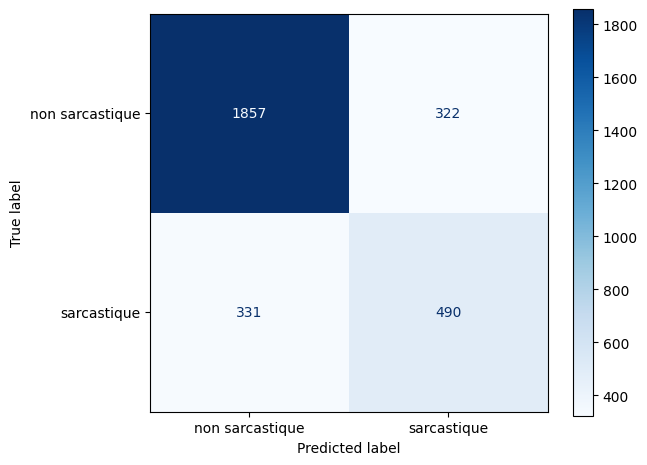

,model,latence_cpu_ms_par_tweet,taille_modele_Mo
0,A_tfidf,2.15,6.51
1,C_aravec_degele_transformer,1.70,7.39
2,D2_attention,120.28,544.72
3,E1_marbert_seed42,102.19,651.44
4,E2_arabert_lam0.3_seed42,119.19,540.86


In [28]:
def cpu_latency_ms(predict_one,samples,warmup=3):
    for text in samples[:warmup]:predict_one(text)
    st=time.perf_counter()
    for text in samples:predict_one(text)
    return 1000*(time.perf_counter()-st)/len(samples)

if RUN_GENERALIZATION:
    # Classement de décision par F1 val ; les chiffres test restent pour le rapport final.
    tab=pd.DataFrame(RESULTS).dropna(subset=['test_f1_sarc']).copy()
    display(tab[['model','family','val_f1_sarc','test_f1_sarc','test_pr_auc',
                 'train_seconds','trainable_params','threshold']].sort_values('val_f1_sarc',ascending=False))
    chosen=tab.sort_values('val_f1_sarc',ascending=False).iloc[0]['model']
    if chosen not in TEST_SCORES: chosen='A_tfidf'
    print('Modèle retenu sur val :',chosen,'; seuil :',THRESH[chosen])
    cm=confusion_matrix(y_test,TEST_SCORES[chosen]>=THRESH[chosen])
    ConfusionMatrixDisplay(cm,display_labels=['non sarcastique','sarcastique']).plot(cmap='Blues')
    plt.tight_layout();plt.savefig(ROOT/'figures'/'G_matrice_confusion.png',dpi=180);plt.show()

    # Latence mono-tweet sur CPU et taille du modèle pour chaque famille finale.
    samples=test.tweet.head(20).tolist()
    final_names=['A_tfidf']
    if RUN_STATIC:final_names.append(best_c)
    if RUN_FROZEN:final_names.append(best_d)
    if RUN_FINETUNE:final_names += [best_e1['model'],best_e2['model']]
    cost=[]
    for name in final_names:
        if name=='A_tfidf':
            fe,lr=MODELS[name]
            predict=lambda t:lr.predict_proba(fe.transform([preprocess(t,'tfidf')]))[0,1]
            size=(ROOT/'models'/'A_tfidf.joblib').stat().st_size/1e6
            restore=None
        elif name.startswith('C_'):
            model=MODELS[name].to('cpu').eval()
            def predict(t,model=model):
                with torch.inference_mode():
                    x=torch.tensor([encode_words(t)])
                    return model(x).softmax(-1)[0,1].item()
            size=(ROOT/'models'/f'{name}.pt').stat().st_size/1e6
            restore=model
        elif name.startswith('D1_'):
            tok,enc,lr,pool=MODELS[name];enc.to('cpu').eval()
            def predict(t,tok=tok,enc=enc,lr=lr,pool=pool):
                batch=encode_texts(tok,[plm_preprocess(t,ARABERT)])
                with torch.inference_mode():h=enc(**batch).last_hidden_state
                z=h[:,0] if pool=='cls' else (h*batch['attention_mask'].unsqueeze(-1)).sum(1)/batch['attention_mask'].sum(1).unsqueeze(-1)
                return lr.predict_proba(z.numpy())[0,1]
            size=sum(p.numel()*p.element_size() for p in enc.parameters())/1e6
            size+=(ROOT/'models'/f'{name}_lr.joblib').stat().st_size/1e6
            restore=enc
        elif name=='D2_attention':
            tok,enc,head=MODELS[name];enc.to('cpu').eval();head.to('cpu').eval()
            def predict(t,tok=tok,enc=enc,head=head):
                batch=encode_texts(tok,[plm_preprocess(t,ARABERT)])
                with torch.inference_mode():
                    h=enc(**batch).last_hidden_state
                    return head(h,batch['attention_mask']).softmax(-1)[0,1].item()
            size=sum(p.numel()*p.element_size() for p in enc.parameters())/1e6
            size+=(ROOT/'models'/'D2_attention.pt').stat().st_size/1e6
            restore=(enc,head)
        else:
            tok,model,remove=MODELS.get(name) or load_plm_checkpoint(name)
            model.to('cpu').eval()
            def predict(t,tok=tok,model=model,remove=remove):
                batch=encode_texts(tok,[plm_preprocess(t,tok.name_or_path,remove)])
                with torch.inference_mode():return model(**batch)[0].softmax(-1)[0,1].item()
            size=(ROOT/'models'/f'{name}.pt').stat().st_size/1e6
            restore=model
        latency=cpu_latency_ms(predict,samples)
        cost.append({'model':name,'latence_cpu_ms_par_tweet':latency,'taille_modele_Mo':size})
        if restore is not None:
            if isinstance(restore,tuple):
                for module in restore:module.to(dev)
            else:restore.to(dev)
    display(pd.DataFrame(cost).round(2))
    pd.DataFrame(cost).to_csv(ROOT/'results'/'G_cout_modeles.csv',index=False)

### Réponses guidées Q1–Q12 (à finaliser après exécution)

1. **Q1.** Reporter les taux train/val/test ci-dessus, par dialecte. Le classifieur toujours négatif peut avoir une bonne accuracy mais F1 sarcastique nul ; choisir le F1 sarcastique, complété par PR-AUC et macro-F1.
2. **Q2.** Utiliser le tableau des taux conditionnels et celui des règles. Un score élevé d'une règle superficielle signale un risque de raccourci ; vérifier F3.
3. **Q3.** TF-IDF/static : normalisation légère avec conservation des marqueurs ; PLM : texte presque brut. Reporter la différence chiffrée `A_tfidf_sans_indices` et F4.
4. **Q4.** Comparer `B1_nli_ar/fr/en`. Un NLI évalue l'implication entre tweet et hypothèse grâce aux représentations contextuelles ; la formulation modifie les scores et le seuil.
5. **Q5.** Précision/rappel/F1 dans `results.csv`. Un sentiment négatif n'est pas synonyme de sarcasme. Le modèle de sentiment peut avoir rencontré des tweets apparentés : contamination possible.
6. **Q6.** Comparer `C_imbalance_weighted/oversample/standard`. Le sur-échantillonnage avant split dupliquerait des observations dans val.
7. **Q7.** Comparer C1/C2/C3 et C3 sans position ; confronter les poids d'attention aux cinq exemples visualisés.
8. **Q8.** Comparer D et E1 avec F1, paramètres entraînés et secondes. Motiver AraBERT contre MARBERT par les valeurs observées.
9. **Q9.** Comparer E2 aux E1 par λ ; une tâche auxiliaire aide si ses indices sont utiles et peut nuire si ses gradients entrent en conflit.
10. **Q10.** Lire le graphique F1=f(seuil) et l'écart entre seuil val et optimum test **a posteriori** ; proposer monitoring du prior et recalibration sur nouvelles données étiquetées.
11. **Q11.** Lire les comptes `magreb` et les résultats F2. Pour le Maroc, constituer un échantillon marocain représentatif, annoté séparément, avant déploiement.
12. **Q12.** Annoter `F6_30_erreurs_a_annoter.csv`, calculer la part du bruit d'annotation et justifier le modèle final par score, robustesse, taille et latence. Ne pas attribuer des catégories sans examen humain.

**Limites à documenter :** coût des modèles, éventuel recouvrement du modèle de sentiment avec ArSarcasm, incertitude sur les labels, mélange des dialectes et disponibilité variable des GPU.